# Part C · Prove the palette, don't claim it

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 3

About 1 man in 12 and 1 woman in 200 has a colour-vision deficiency (CVD). In a class of 60, that's about
three people who can't read a red/green chart, and they won't say so. The simulation will.

`vizlib.simulate_cvd()` applies the Machado, Oliveira & Fernandes (2009) severity-1.0 matrices in linear
RGB. `vizlib.worst_pair()` compares **every** pair of colours in OKLab, where one ΔE threshold means the
same thing for every hue: ≥ 15 clear, ≥ 8 OK after simulation, 6–8 only with a second channel, < 6 the
same colour.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from vizlib import PALETTE, delta_e, save_fig, simulate_cvd, style_defaults, verdict, worst_pair

CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)
style_defaults(dpi=100)

MY_PALETTE = ["#1F77B4", "#FF7F0E", "#2CA02C", "#D62728"]     # matplotlib tab10, first four
MY_LABEL = "matplotlib tab10, first four (the default I'd normally use)"
COURSE = PALETTE["series"] + [PALETTE["series_4th"]]
KINDS = ["normal", "deutan", "protan", "tritan"]

**Why tab10.** It's the palette matplotlib hands out when you don't choose one, so it's the one I've
actually been using without thinking. Blue, orange, green and red look clearly distinct on my screen. I
don't already know it to be safe, which is what question 1 asks for.

## 1 + 2 · Before and after, both palettes

'charts\\partC_palette.png'

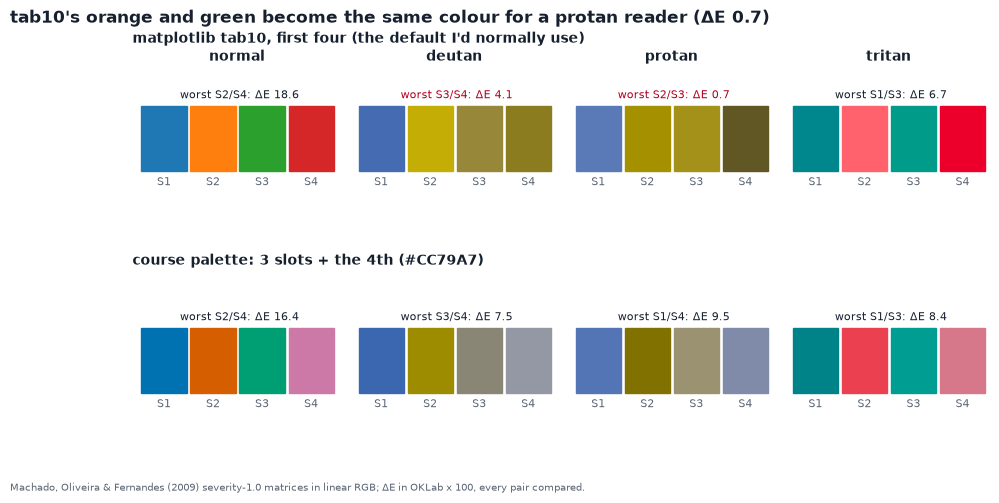

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(11, 4.4), gridspec_kw=dict(wspace=0.08, hspace=0.9))
for row, (pal, label) in enumerate([(MY_PALETTE, MY_LABEL), (COURSE, "course palette: 3 slots + the 4th (#CC79A7)")]):
    for col, kind in enumerate(KINDS):
        ax = axes[row, col]
        shown = pal if kind == "normal" else simulate_cvd(pal, kind)
        for i, c in enumerate(shown):
            ax.add_patch(plt.Rectangle((i, 0), 0.92, 1, color=c))
            ax.text(i + 0.46, -0.22, f"S{i + 1}", ha="center", fontsize=8, color=PALETTE["ink_soft"])
        i, j, _, _, d = worst_pair(pal, None if kind == "normal" else kind)
        ax.text(2, 1.12, f"worst S{i}/S{j}: ΔE {d:.1f}", ha="center", fontsize=8,
                color="#B00020" if d < 6 else PALETTE["ink"])
        ax.set_xlim(-0.1, len(pal))
        ax.set_ylim(-0.4, 1.4)
        ax.axis("off")
        if row == 0:
            ax.set_title(kind, fontsize=10, loc="center", pad=14)
    axes[row, 0].text(-0.02, 1.32, label, transform=axes[row, 0].transAxes, fontsize=10, fontweight="bold")
fig.suptitle("tab10's orange and green become the same colour for a protan reader (ΔE 0.7)",
             x=0.01, ha="left", fontweight="bold", y=1.04)
save_fig(fig, CHARTS / "partC_palette.png",
         note="Machado, Oliveira & Fernandes (2009) severity-1.0 matrices in linear RGB; ΔE in OKLab x 100, every pair compared.")

## 3 · The worst pair in each palette

In [3]:
rows = []
for name, pal in [("tab10 (first four)", MY_PALETTE), ("course, 3 slots", PALETTE["series"]), ("course + 4th slot", COURSE)]:
    for kind in KINDS:
        i, j, a, b, d = worst_pair(pal, None if kind == "normal" else kind)
        rows.append({"palette": name, "vision": kind, "closest pair": f"S{i} {a} / S{j} {b}",
                     "ΔE": round(d, 1), "verdict": verdict(d)})
table = pd.DataFrame(rows)
table

,palette,vision,closest pair,ΔE,verdict
0,tab10 (first four),normal,S2 #FF7F0E / S4 #D62728,18.6,clear
1,tab10 (first four),deutan,S3 #2CA02C / S4 #D62728,4.1,FAILS — same colour
2,tab10 (first four),protan,S2 #FF7F0E / S3 #2CA02C,0.7,FAILS — same colour
3,tab10 (first four),tritan,S1 #1F77B4 / S3 #2CA02C,6.7,needs a second channel
4,"course, 3 slots",normal,S1 #0072B2 / S3 #009E73,18.7,clear
5,"course, 3 slots",deutan,S2 #D55E00 / S3 #009E73,11.0,ok
6,"course, 3 slots",protan,S2 #D55E00 / S3 #009E73,13.0,ok
7,"course, 3 slots",tritan,S1 #0072B2 / S3 #009E73,8.4,ok
8,course + 4th slot,normal,S2 #D55E00 / S4 #CC79A7,16.4,clear
9,course + 4th slot,deutan,S3 #009E73 / S4 #CC79A7,7.5,needs a second channel


**tab10 fails twice.** Under **protanopia**, S2 orange and S3 green collapse to **ΔE 0.7**, literally the
same colour. Under **deuteranopia**, S3 green and S4 red fall to **ΔE 4.1**, also a fail. The two most
common forms of CVD each erase one pair. A chart that coloured "on track" green and "off track" red would
be unreadable to roughly 1 man in 12.

**The course palette's three slots pass everything** (worst ΔE 8.4, under tritanopia). **The fourth slot
is its weak point:** under **deuteranopia**, S3 green (#009E73) and S4 pink (#CC79A7) fall to **ΔE 7.5**,
below the 8 target and in the "needs a second channel" band. So the rule for that colour is: **#CC79A7
can never be the only thing separating a series.** Wherever it's used, the series also needs a different
marker shape or a direct label. It's also the weakest on contrast against white (3.06:1, just over the 3:1
minimum for graphics, measured below), so it's not a colour for thin lines or small text.

In [4]:
def contrast_on_white(hexc):
    """WCAG 2 contrast ratio against #FFFFFF."""
    c = [int(hexc[i:i + 2], 16) / 255 for i in (1, 3, 5)]
    c = [x / 12.92 if x <= 0.04045 else ((x + 0.055) / 1.055) ** 2.4 for x in c]
    return 1.05 / (0.2126 * c[0] + 0.7152 * c[1] + 0.0722 * c[2] + 0.05)


for c in COURSE:
    print(f"{c} contrast on white {contrast_on_white(c):.2f}:1")
print("deutan simulation of the course palette:", dict(zip(COURSE, simulate_cvd(COURSE, "deutan"))))

#0072B2 contrast on white 5.19:1
#D55E00 contrast on white 3.87:1
#009E73 contrast on white 3.42:1
#CC79A7 contrast on white 3.06:1
deutan simulation of the course palette: {'#0072B2': '#3B67B1', '#D55E00': '#9E8C00', '#009E73': '#8A8676', '#CC79A7': '#9498A5'}


## 4 · My rule for more than three categories

**Up to three categories, colour carries identity on its own. A fourth category gets colour *plus* a
second channel (marker shape or a direct label), never colour alone. Beyond four, I stop adding hues: I
grey the context and colour only the one or two categories the title is about, or split them into small
multiples, or label every line at its end.** A bigger palette only moves the collapse further down the
list. The fix is a channel that doesn't depend on hue.

Part D applies this: its scatter uses two colours **and** two marker shapes, and its box plot needs no
colour at all, because the ward names on the axis already carry the identity.